# Análise de Vendas - Mercado do Ponto

Este notebook analisa o **Mercado do Ponto** diretamente a partir da camada **Gold** do PostgreSQL. O período é identificado dinamicamente pelos dados disponíveis, sem restringir a análise a março de 2026.

**Escopo das fontes:** vendas por horário representam o faturamento operacional agregado; transações de pagamentos representam somente as operações presentes na base de meios de pagamento. Esses valores não são intercambiáveis.

**Transparência:** os dados de vendas por horário de abril a setembro de 2026 são **sintéticos** para demonstração da plataforma, não resultados financeiros reais auditados. As conclusões devem considerar essa limitação.


## Imports e conexão com PostgreSQL


In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import psycopg
from dotenv import load_dotenv

pd.set_option('display.max_columns', None)

candidatos = [Path.cwd() / '.env', Path.cwd().parent / '.env']
ENV_PATH = next((p for p in candidatos if p.is_file()), None)
if ENV_PATH is None:
    raise FileNotFoundError('Arquivo .env não encontrado no diretório atual ou no diretório pai.')
load_dotenv(ENV_PATH, override=True)
DB_CONFIG = {
    'host': os.getenv('DB_HOST', '127.0.0.1'),
    'port': os.getenv('DB_PORT', '5434'),
    'dbname': os.getenv('DB_NAME', 'mercado_analytics'),
    'user': os.getenv('DB_USER', 'postgres'),
    'password': os.getenv('DB_PASSWORD'),
}
print(f'Conexão: {DB_CONFIG["host"]}:{DB_CONFIG["port"]}/{DB_CONFIG["dbname"]}')
print(f'.env carregado: {ENV_PATH.resolve()}')


Conexão: localhost:5434/mercado_analytics
.env carregado: C:\Users\rpb\Documents\plataforma-dados-analise-varejo\plataforma-dados-analise-varejo\.env


## Funções auxiliares


In [2]:
def consultar_dataframe(query: str) -> pd.DataFrame:
    with psycopg.connect(**DB_CONFIG) as conn:
        with conn.cursor() as cur:
            cur.execute(query)
            rows = cur.fetchall()
            columns = [desc.name for desc in cur.description]
    return pd.DataFrame(rows, columns=columns)


## Load Data - camada Gold do PostgreSQL


In [3]:
SQL_VENDAS_CARTOES = """
SELECT
    f.data_key + f.hora_key * INTERVAL '1 hour' AS "Data da Transação",
    b.bandeira AS "Bandeira",
    p.forma_pagamento AS "Forma de Pagamento",
    f.valor_bruto AS "Valor Bruto",
    f.valor_taxa AS "Valor Taxa",
    f.valor_liquido AS "Valor Líquido",
    f.status AS "Status"
FROM gold.fato_pagamentos f
JOIN gold.dim_pagamento p ON p.pagamento_key = f.pagamento_key
LEFT JOIN gold.dim_bandeira b ON b.bandeira_key = f.bandeira_key
ORDER BY 1;
"""
SQL_VENDAS_HORARIO = """
SELECT
    f.mes, f.hora_key AS hora, h.turno,
    f.qtd_clientes, f.qtd_produtos, f.total_venda
FROM gold.fato_vendas_horario f
JOIN gold.dim_horario h ON h.hora_key = f.hora_key
ORDER BY f.mes, f.hora_key;
"""
df_vendas_cartoes = consultar_dataframe(SQL_VENDAS_CARTOES)
df_vendas_por_horario = consultar_dataframe(SQL_VENDAS_HORARIO)
print(f'Pagamentos carregados da Gold: {len(df_vendas_cartoes):,}')
print(f'Registros horários carregados da Gold: {len(df_vendas_por_horario):,}')


Pagamentos carregados da Gold: 14,845
Registros horários carregados da Gold: 119


## Visualization

### Vendas Cartões

In [4]:
df_vendas_cartoes.head()

,Data da Transação,Bandeira,Forma de Pagamento,Valor Bruto,Valor Taxa,Valor Líquido,Status
0,2026-01-01 08:00:00,Visa,Crédito,53.07,2.48,50.59,Aprovada
1,2026-01-01 10:00:00,Não se aplica,Pix,24.98,0.25,24.73,Aprovada
2,2026-01-01 10:00:00,Visa,Crédito,76.12,3.56,72.56,Aprovada
3,2026-01-01 10:00:00,Visa,Crédito,7.49,0.35,7.14,Aprovada
4,2026-01-01 10:00:00,Não se aplica,Pix,39.94,0.40,39.54,Aprovada


### Vendas por Horário

In [5]:
df_vendas_por_horario.head()

,mes,hora,turno,qtd_clientes,qtd_produtos,total_venda
0,2026-01-01,8,Manhã,0,0,0.00
1,2026-01-01,9,Manhã,9,15,119.70
2,2026-01-01,10,Manhã,26,57,333.55
3,2026-01-01,11,Manhã,83,157,1129.32
4,2026-01-01,12,Tarde,129,280,1774.58


## Infos

### Vendas por Horário

In [6]:
df_vendas_por_horario.info()

<class 'pandas.DataFrame'>
RangeIndex: 119 entries, 0 to 118
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   mes           119 non-null    object
 1   hora          119 non-null    int64 
 2   turno         119 non-null    str   
 3   qtd_clientes  119 non-null    int64 
 4   qtd_produtos  119 non-null    int64 
 5   total_venda   119 non-null    object
dtypes: int64(3), object(2), str(1)
memory usage: 5.7+ KB


### Vendas Cartões

In [7]:
df_vendas_cartoes.info()

<class 'pandas.DataFrame'>
RangeIndex: 14845 entries, 0 to 14844
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Data da Transação   14845 non-null  datetime64[us]
 1   Bandeira            14845 non-null  str           
 2   Forma de Pagamento  14845 non-null  str           
 3   Valor Bruto         14845 non-null  object        
 4   Valor Taxa          14845 non-null  object        
 5   Valor Líquido       14845 non-null  object        
 6   Status              14845 non-null  str           
dtypes: datetime64[us](1), object(3), str(3)
memory usage: 812.0+ KB


- Os dados agora são consumidos da camada **Gold** do PostgreSQL e já chegam tipados e tratados pelo pipeline. O notebook não deve repetir a limpeza que pertence às camadas de Engenharia de Dados.


## Preparação analítica


In [8]:
df_vendas_por_horario['mes'] = pd.to_datetime(df_vendas_por_horario['mes'])
df_vendas_por_horario['hora_int'] = df_vendas_por_horario['hora'].astype(int)
df_vendas_por_horario['hora'] = pd.to_datetime(df_vendas_por_horario['hora_int'], unit='h', origin=pd.Timestamp('2000-01-01'))
for col in ['total_venda', 'qtd_clientes', 'qtd_produtos']:
    df_vendas_por_horario[col] = pd.to_numeric(df_vendas_por_horario[col], errors='coerce')

df_vendas_cartoes['Data da Transação'] = pd.to_datetime(df_vendas_cartoes['Data da Transação'])
for col in ['Valor Bruto', 'Valor Taxa', 'Valor Líquido']:
    df_vendas_cartoes[col] = pd.to_numeric(df_vendas_cartoes[col], errors='coerce')
df_vendas_cartoes['Bandeira'] = df_vendas_cartoes['Bandeira'].fillna('Não informada')

if df_vendas_por_horario.empty:
    raise ValueError('A tabela gold.fato_vendas_horario está vazia. Execute a pipeline primeiro.')

meses = sorted(df_vendas_por_horario['mes'].dt.to_period('M').dropna().unique())
periodo_inicio, periodo_fim = meses[0], meses[-1]
print(f'Período de vendas por horário: {periodo_inicio} a {periodo_fim} ({len(meses)} meses disponíveis)')
if not df_vendas_cartoes.empty:
    print('Período de pagamentos:', df_vendas_cartoes['Data da Transação'].min().date(), 'a', df_vendas_cartoes['Data da Transação'].max().date())
print('Atenção: vendas por horário de abr-set/2026 são sintéticas.')


Período de vendas por horário: 2026-01 a 2026-09 (9 meses disponíveis)
Período de pagamentos: 2026-01-01 a 2026-09-30
Atenção: vendas por horário de abr-set/2026 são sintéticas.


## Perguntas de Negócio

### 1. Qual é o faturamento mensal no período disponível?


,faturamento,crescimento_%
mes,,
2026-01-01,19720.63,NaN
2026-02-01,35798.45,81.53
2026-03-01,39065.58,9.13
2026-04-01,39831.89,1.96
2026-05-01,42305.64,6.21
2026-06-01,36357.24,-14.06
2026-07-01,44273.24,21.77
2026-08-01,41104.56,-7.16
2026-09-01,46363.86,12.79


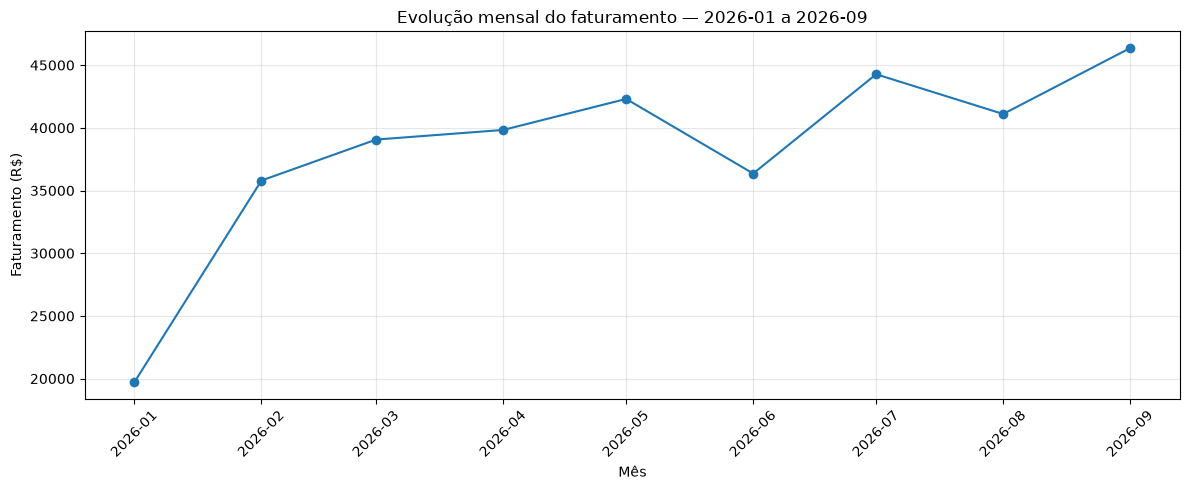

Total no período: R$ 344,821.09


In [9]:
faturamento_mes = df_vendas_por_horario.groupby('mes')['total_venda'].sum().sort_index()
crescimento_pct = faturamento_mes.pct_change() * 100
resultado = pd.DataFrame({'faturamento': faturamento_mes, 'crescimento_%': crescimento_pct})
display(resultado.round(2))
plt.figure(figsize=(12, 5))
plt.plot(resultado.index, resultado['faturamento'], marker='o')
plt.title(f'Evolução mensal do faturamento — {periodo_inicio} a {periodo_fim}')
plt.xlabel('Mês'); plt.ylabel('Faturamento (R$)'); plt.grid(alpha=0.3)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
print(f'Total no período: R$ {faturamento_mes.sum():,.2f}')


### 2. Qual foi o faturamento por hora no período disponível?


In [10]:
faturamento_hora = df_vendas_por_horario.groupby("hora")["total_venda"].sum()

print("\nFaturamento por hora:")
print(faturamento_hora)


Faturamento por hora:
hora
2000-01-01 08:00:00      460.46
2000-01-01 09:00:00     6796.22
2000-01-01 10:00:00    23673.84
2000-01-01 11:00:00    36829.52
2000-01-01 12:00:00    43700.74
2000-01-01 13:00:00    29719.05
2000-01-01 14:00:00    24436.19
2000-01-01 15:00:00    25937.74
2000-01-01 16:00:00    27005.98
2000-01-01 17:00:00    37234.15
2000-01-01 18:00:00    39820.32
2000-01-01 19:00:00    38092.56
2000-01-01 20:00:00    10375.65
2000-01-01 21:00:00      738.67
Name: total_venda, dtype: float64


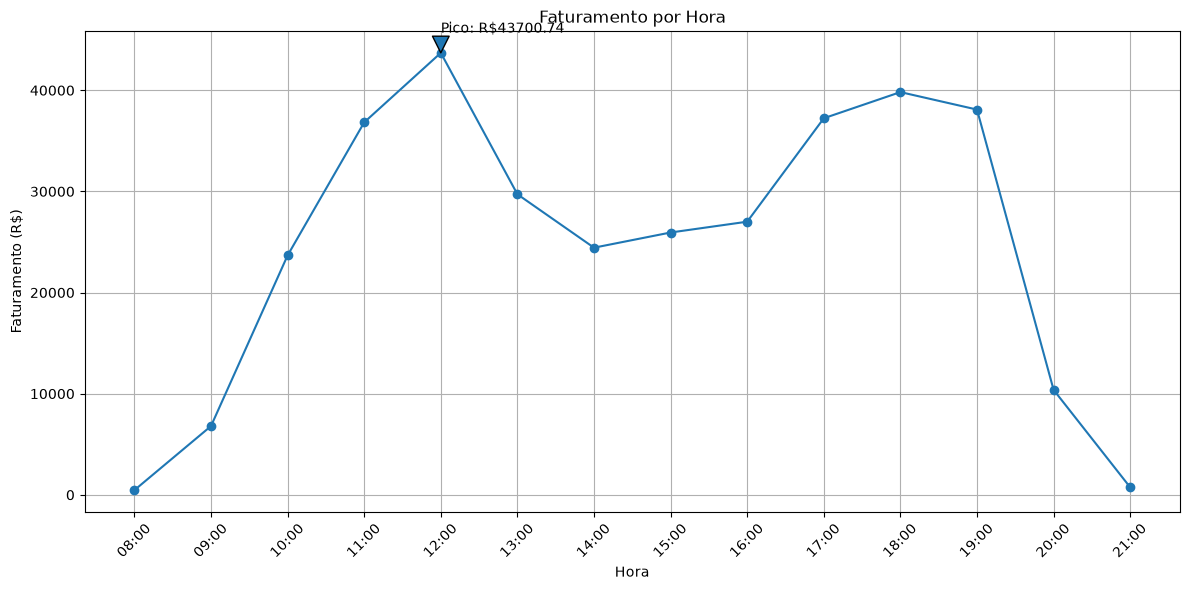

In [11]:
faturamento_hora = faturamento_hora.sort_index()
horas_formatadas = faturamento_hora.index.strftime('%H:%M')

plt.figure(figsize=(12, 6))

plt.plot(horas_formatadas, faturamento_hora.values, marker='o')

pico_idx = faturamento_hora.idxmax()
pico_valor = faturamento_hora.max()
pico_hora = pico_idx.strftime('%H:%M')

plt.annotate(
    f'Pico: R${pico_valor:.2f}',
    xy=(pico_hora, pico_valor),
    xytext=(pico_hora, pico_valor + 2000),
    arrowprops=dict()
)

plt.title('Faturamento por Hora')
plt.xlabel('Hora')
plt.ylabel('Faturamento (R$)')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()

plt.show()

### 3. Quais foram os horários de pico?

In [12]:
top_horarios = faturamento_hora.sort_values(ascending=False).head(5)

print("\nTop 5 horários de venda:")
print(top_horarios)



Top 5 horários de venda:
hora
2000-01-01 12:00:00    43700.74
2000-01-01 18:00:00    39820.32
2000-01-01 19:00:00    38092.56
2000-01-01 17:00:00    37234.15
2000-01-01 11:00:00    36829.52
Name: total_venda, dtype: float64


### 4. Qual a quantidade de clientes por hora?

In [13]:
clientes_hora = df_vendas_por_horario.groupby('hora')['qtd_clientes'].sum()

print("\nClientes por hora:")
print(clientes_hora)


Clientes por hora:
hora
2000-01-01 08:00:00      40
2000-01-01 09:00:00     412
2000-01-01 10:00:00    1479
2000-01-01 11:00:00    2374
2000-01-01 12:00:00    2669
2000-01-01 13:00:00    2065
2000-01-01 14:00:00    1699
2000-01-01 15:00:00    1850
2000-01-01 16:00:00    1756
2000-01-01 17:00:00    2451
2000-01-01 18:00:00    2535
2000-01-01 19:00:00    2543
2000-01-01 20:00:00     513
2000-01-01 21:00:00      35
Name: qtd_clientes, dtype: int64


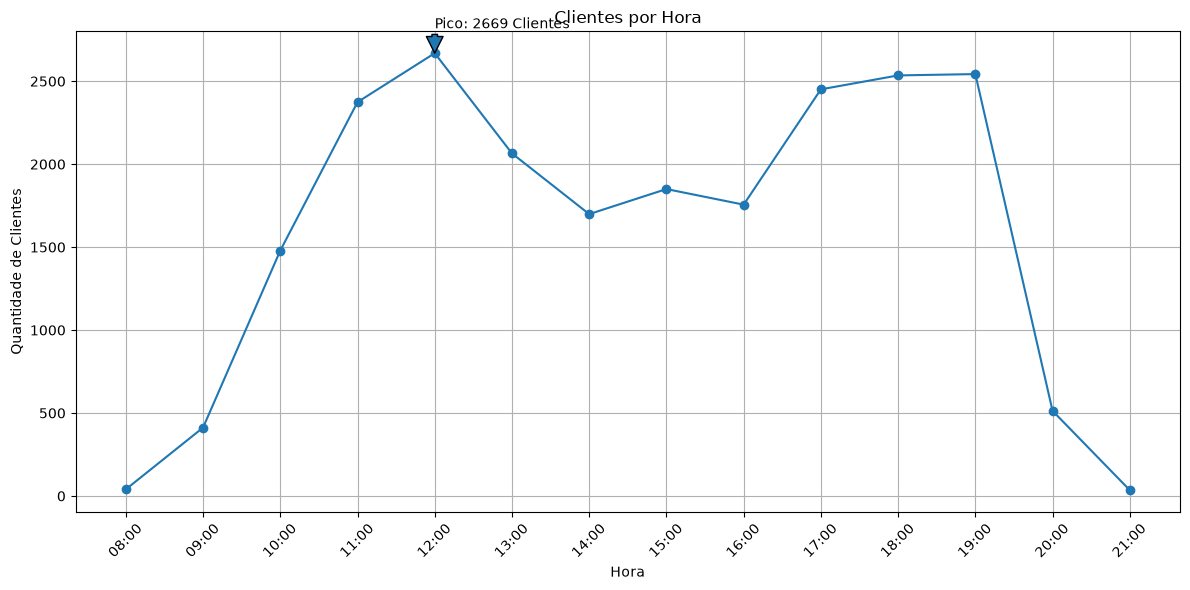

In [14]:
clientes_hora = clientes_hora.sort_index()
horas_formatadas = clientes_hora.index.strftime('%H:%M')

plt.figure(figsize=(12, 6))

plt.plot(horas_formatadas, clientes_hora.values, marker='o')

pico_idx = clientes_hora.idxmax()
pico_valor = clientes_hora.max()
pico_hora = pico_idx.strftime('%H:%M')

plt.annotate(
    f'Pico: {pico_valor} Clientes',
    xy=(pico_hora, pico_valor),
    xytext=(pico_hora, pico_valor + 150),
    arrowprops=dict()
)

plt.title('Clientes por Hora')
plt.xlabel('Hora')
plt.ylabel('Quantidade de Clientes')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()

plt.show()

### 5. Qual o Ticket Médio por hora?

In [15]:
df_vendas_por_horario.head()

,mes,hora,turno,qtd_clientes,qtd_produtos,total_venda,hora_int
0,2026-01-01,2000-01-01 08:00:00,Manhã,0,0,0.00,8
1,2026-01-01,2000-01-01 09:00:00,Manhã,9,15,119.70,9
2,2026-01-01,2000-01-01 10:00:00,Manhã,26,57,333.55,10
3,2026-01-01,2000-01-01 11:00:00,Manhã,83,157,1129.32,11
4,2026-01-01,2000-01-01 12:00:00,Tarde,129,280,1774.58,12


In [16]:
# Ticket médio ponderado: faturamento total / clientes totais por hora.
df_vendas_por_horario['ticket_medio'] = df_vendas_por_horario['total_venda'].div(df_vendas_por_horario['qtd_clientes'].replace(0, np.nan))
resumo_hora = df_vendas_por_horario.groupby('hora').agg(total_venda=('total_venda','sum'), qtd_clientes=('qtd_clientes','sum'), qtd_produtos=('qtd_produtos','sum'))
ticket_hora = resumo_hora['total_venda'].div(resumo_hora['qtd_clientes'].replace(0, np.nan))
print('Ticket médio ponderado por hora:')
print(ticket_hora.sort_values(ascending=False))


Ticket médio ponderado por hora:
hora
2000-01-01 21:00:00    21.104857
2000-01-01 20:00:00    20.225439
2000-01-01 09:00:00    16.495680
2000-01-01 12:00:00    16.373451
2000-01-01 10:00:00    16.006653
2000-01-01 18:00:00    15.708213
2000-01-01 11:00:00    15.513698
2000-01-01 16:00:00    15.379260
2000-01-01 17:00:00    15.191412
2000-01-01 19:00:00    14.979379
2000-01-01 13:00:00    14.391792
2000-01-01 14:00:00    14.382690
2000-01-01 15:00:00    14.020400
2000-01-01 08:00:00    11.511500
dtype: float64


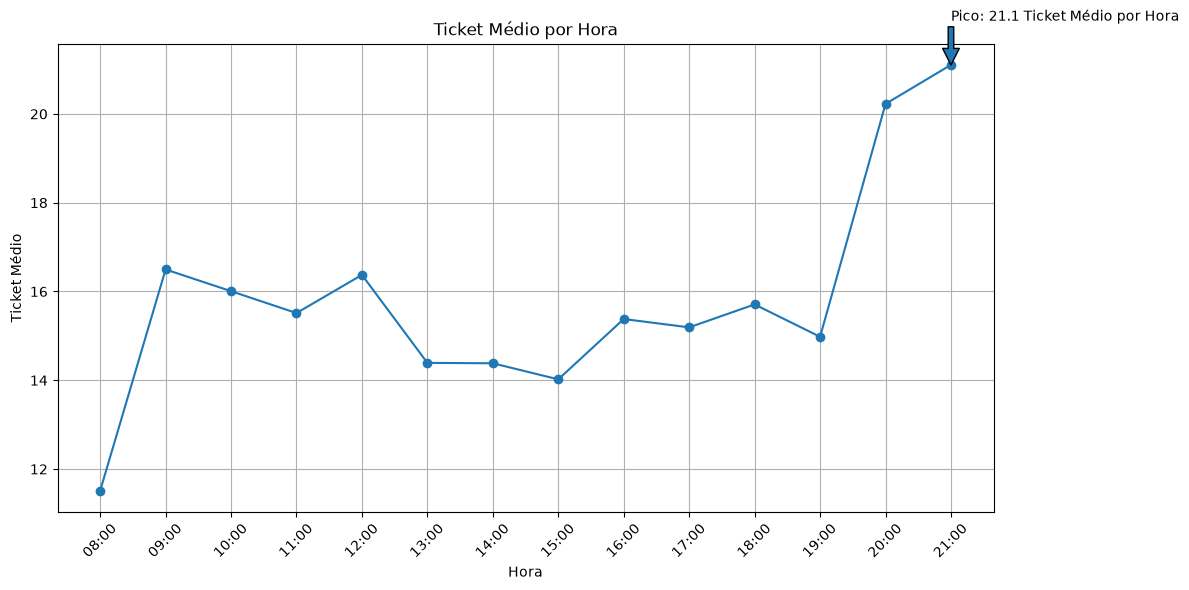

In [17]:
ticket_hora = ticket_hora.sort_index()
horas_formatadas = ticket_hora.index.strftime('%H:%M')

plt.figure(figsize=(12, 6))

plt.plot(horas_formatadas, ticket_hora.values, marker='o')

pico_idx = ticket_hora.idxmax()
pico_valor = ticket_hora.max().round(2)
pico_hora = pico_idx.strftime('%H:%M')

plt.annotate(
    f'Pico: {pico_valor} Ticket Médio por Hora',
    xy=(pico_hora, pico_valor),
    xytext=(pico_hora, pico_valor + 1),
    arrowprops=dict()
)

plt.title('Ticket Médio por Hora')
plt.xlabel('Hora')
plt.ylabel('Ticket Médio')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()

plt.show()

### 6. Qual a média de produtos por cliente?

In [18]:
# Média ponderada de produtos por cliente, por horário.
df_vendas_por_horario['prod_por_cliente'] = df_vendas_por_horario['qtd_produtos'].div(df_vendas_por_horario['qtd_clientes'].replace(0, np.nan))
produtos_hora = resumo_hora['qtd_produtos'].div(resumo_hora['qtd_clientes'].replace(0, np.nan))
print('Produtos por cliente por hora:')
print(produtos_hora)


Produtos por cliente por hora:
hora
2000-01-01 08:00:00    2.375000
2000-01-01 09:00:00    2.742718
2000-01-01 10:00:00    2.379310
2000-01-01 11:00:00    2.554339
2000-01-01 12:00:00    2.793181
2000-01-01 13:00:00    2.482809
2000-01-01 14:00:00    2.505592
2000-01-01 15:00:00    2.508108
2000-01-01 16:00:00    2.616173
2000-01-01 17:00:00    2.549980
2000-01-01 18:00:00    2.591321
2000-01-01 19:00:00    2.294534
2000-01-01 20:00:00    2.481481
2000-01-01 21:00:00    2.342857
dtype: float64


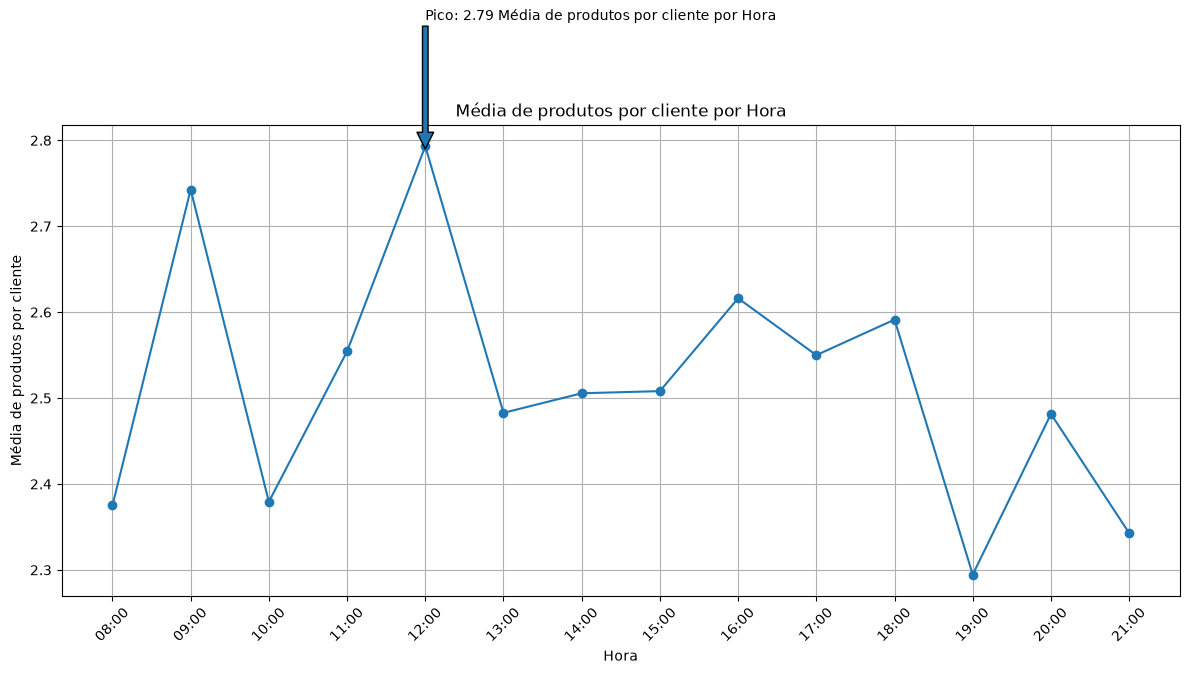

In [19]:
produtos_hora = produtos_hora.sort_index()
horas_formatadas = produtos_hora.index.strftime('%H:%M')

plt.figure(figsize=(12, 7))

plt.plot(horas_formatadas, produtos_hora.values, marker='o')

pico_idx = produtos_hora.idxmax()
pico_valor = produtos_hora.max().round(2)
pico_hora = pico_idx.strftime('%H:%M')

plt.annotate(
    f'Pico: {pico_valor} Média de produtos por cliente por Hora',
    xy=(pico_hora, pico_valor),
    xytext=(pico_hora, pico_valor + 0.15),
    arrowprops=dict()
)

plt.title('Média de produtos por cliente por Hora')
plt.xlabel('Hora')
plt.ylabel('Média de produtos por cliente')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()

plt.show()

### 7. Qual o Ticket Médio apenas na vendas da maquininha?

In [20]:
df_vendas_cartoes['mes_ref'] = df_vendas_cartoes['Data da Transação'].dt.to_period('M')

ticket_mensal = df_vendas_cartoes.groupby('mes_ref').agg(
    faturamento_total=('Valor Bruto', 'sum'),
    qtd_transacoes=('Valor Bruto', 'count')
)

ticket_mensal['ticket_medio'] = (
    ticket_mensal['faturamento_total'] / ticket_mensal['qtd_transacoes']
)

ticket_mensal = ticket_mensal.reset_index()

print("\nTicket médio por mês:")
print(ticket_mensal)


Ticket médio por mês:
   mes_ref  faturamento_total  qtd_transacoes  ticket_medio
0  2026-01           20892.20            1313     15.911805
1  2026-02           18129.21            1151     15.750834
2  2026-03           28710.14            1762     16.294064
3  2026-04           30606.06            1878     16.297157
4  2026-05           31361.18            1874     16.734888
5  2026-06           28873.65            1761     16.396167
6  2026-07           28761.55            1752     16.416410
7  2026-08           28302.99            1738     16.284804
8  2026-09           26779.47            1616     16.571454


### 8. Qual é o volume bruto por forma de pagamento na base de transações?


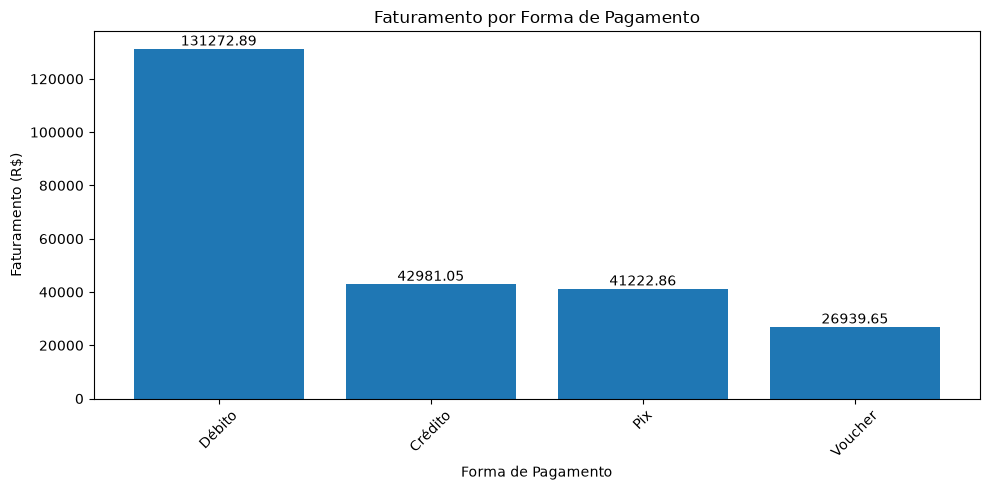

In [21]:
pagamentos = df_vendas_cartoes.groupby('Forma de Pagamento')['Valor Bruto'].sum()
pagamentos = pagamentos.sort_values(ascending=False)
plt.figure(figsize=(10, 5))
bars = plt.bar(pagamentos.index, pagamentos.values)

for bar in bars:
    altura = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        altura,
        f'{altura:.2f}',
        ha='center',
        va='bottom'
    )

plt.title('Faturamento por Forma de Pagamento')
plt.xlabel('Forma de Pagamento')
plt.ylabel('Faturamento (R$)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### 9. Qual é o volume bruto por bandeira na base de transações?


In [22]:
bandeiras = df_vendas_cartoes.groupby('Bandeira')['Valor Bruto'].sum()

print("\nFaturamento por bandeira:")
print(bandeiras.sort_values(ascending=False))


Faturamento por bandeira:
Bandeira
Mastercard       113050.37
Visa              46815.97
Não se aplica     41222.86
Elo               16007.85
VR                10178.83
Alelo              6075.29
Ticket             6075.04
Pluxee             2973.26
Amex                 16.98
Name: Valor Bruto, dtype: float64


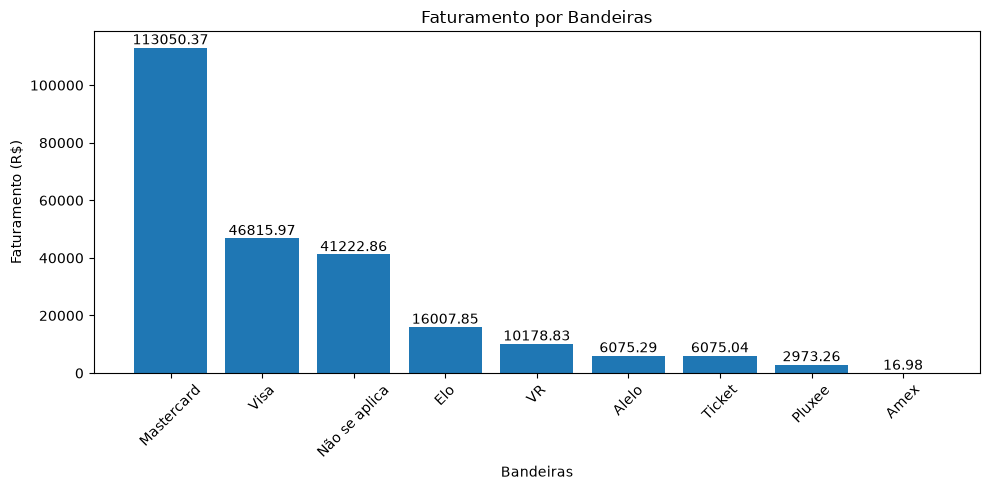

In [23]:
bandeiras = df_vendas_cartoes.groupby('Bandeira')['Valor Bruto'].sum()
bandeiras = bandeiras.sort_values(ascending=False)
plt.figure(figsize=(10, 5))
bars = plt.bar(bandeiras.index, bandeiras.values)

for bar in bars:
    altura = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        altura,
        f'{altura:.2f}',
        ha='center',
        va='bottom'
    )

plt.title('Faturamento por Bandeiras')
plt.xlabel('Bandeiras')
plt.ylabel('Faturamento (R$)')
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

### 10. Qual o total de taxas?

In [24]:
total_taxas = df_vendas_cartoes['Valor Taxa'].sum()

print("\nTotal pago em taxas:")
print(total_taxas)


Total pago em taxas:
4656.049999999999


### 11. Qual o total da receita líquida?

In [25]:
receita_liquida = df_vendas_cartoes['Valor Líquido'].sum()
receita_bruta = df_vendas_cartoes['Valor Bruto'].sum()

print("\nReceita Bruta:", receita_bruta)
print("Receita Líquida:", receita_liquida)


Receita Bruta: 242416.45
Receita Líquida: 237760.4


### 12. Qual o impacto das taxas sobre o volume bruto de pagamentos?


In [26]:
df_vendas_cartoes[["Forma de Pagamento", "Valor Taxa"]].value_counts()

Forma de Pagamento  Valor Taxa
Voucher             0.00          893
Débito              0.06          460
                    0.14          401
                    0.10          395
                    0.05          319
                                 ... 
Crédito             2.77            1
Voucher             4.08            1
                    0.37            1
Débito              1.40            1
Voucher             0.18            1
Name: count, Length: 578, dtype: int64

In [27]:
impacto_taxa = (total_taxas / receita_bruta) * 100 if receita_bruta else np.nan
print(f'Impacto percentual das taxas sobre o volume bruto dos pagamentos: {impacto_taxa:.2f}%')


Impacto percentual das taxas sobre o volume bruto dos pagamentos: 1.92%


In [28]:
df_kpis_gold = consultar_dataframe('SELECT * FROM gold.vw_kpis;')
df_kpis_gold


,faturamento_loja,clientes,produtos,ticket_medio,volume_cartoes,receita_liquida_cartoes,taxas_cartoes,taxa_efetiva
0,344821.09,22421,56890,15.3793804915035012,242416.45,237760.40,4656.05,0.01920682362933703550


In [29]:
df_vendas_por_horario["total_venda"].sum()/df_vendas_por_horario["qtd_clientes"].sum()

np.float64(15.379380491503506)

In [30]:
df_vendas_por_horario.columns

Index(['mes', 'hora', 'turno', 'qtd_clientes', 'qtd_produtos', 'total_venda',
       'hora_int', 'ticket_medio', 'prod_por_cliente'],
      dtype='str')

In [31]:
df_vendas_por_horario.head()

,mes,hora,turno,qtd_clientes,qtd_produtos,total_venda,hora_int,ticket_medio,prod_por_cliente
0,2026-01-01,2000-01-01 08:00:00,Manhã,0,0,0.00,8,NaN,NaN
1,2026-01-01,2000-01-01 09:00:00,Manhã,9,15,119.70,9,13.300000,1.666667
2,2026-01-01,2000-01-01 10:00:00,Manhã,26,57,333.55,10,12.828846,2.192308
3,2026-01-01,2000-01-01 11:00:00,Manhã,83,157,1129.32,11,13.606265,1.891566
4,2026-01-01,2000-01-01 12:00:00,Tarde,129,280,1774.58,12,13.756434,2.170543


In [32]:
df_vendas_por_horario["qtd_clientes"].sum()

np.int64(22421)

In [33]:
df_vendas_por_horario.groupby(["mes"])["total_venda"].sum()

mes
2026-01-01    19720.63
2026-02-01    35798.45
2026-03-01    39065.58
2026-04-01    39831.89
2026-05-01    42305.64
2026-06-01    36357.24
2026-07-01    44273.24
2026-08-01    41104.56
2026-09-01    46363.86
Name: total_venda, dtype: float64

In [34]:
cobertura = df_vendas_por_horario.groupby(df_vendas_por_horario['mes'].dt.to_period('M')).agg(
    horarios=('hora_int','count'),
    clientes=('qtd_clientes','sum'),
    produtos=('qtd_produtos','sum'),
    faturamento=('total_venda','sum')
)
display(cobertura)


,horarios,clientes,produtos,faturamento
mes,,,,
2026-01,14,1331,3296,19720.63
2026-02,14,2459,6169,35798.45
2026-03,13,2536,6462,39065.58
2026-04,13,2525,6459,39831.89
2026-05,13,2694,6838,42305.64
2026-06,13,2419,6382,36357.24
2026-07,13,2852,7083,44273.24
2026-08,13,2660,6914,41104.56
2026-09,13,2945,7287,46363.86
